more and more like pytorch...

In [60]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

from graphviz import Digraph

def trace(root):
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._children:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    if isinstance(n.data, jnp.ndarray):
      data = jnp.array_str(n.data, precision=4)
      grad = jnp.array_str(n.grad, precision=4)
      dot.node(name = uid, label = "{ %s | data %s | grad %s }" % (n.label, data, grad), shape='record')
    else:
      dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      dot.node(name = uid + n._op, label = n._op)
      dot.edge(uid + n._op, uid)
  for n1, n2 in edges:
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  return dot

In [61]:
import jax
import jax.numpy as jnp

class Tensor:
	def __init__(self, data, 
		_children=(), 
		_op="", 
		label="", 
		dtype = jnp.float32, 
		requires_grad=True
	):
		self._children = set(_children)
		self._op = _op
		self.label = label

		# pytorch based
		self.data, self.shape = self._clean_data(data) # new lightweight Tensor object
		self.dtype = dtype # (float32, int64, etc.)
		self.device = self.data.device if self.shape else "cpu"
		self.requires_grad = requires_grad # default assumes non-constant
		self.grad = jnp.zeros(self.shape) if self.shape else 0
		self.grad_fn = lambda: None
		self.is_leaf = (len(self._children) == 0)
		self.T = self.data.T if self.shape else self.data
		self.ndim = len(self.shape)
		self.is_cuda = "Cuda" in str(self.data.device) if self.shape else False

	# pytorch
	def size(self):
		return self.shape
	
	def numel(self):
		return jnp.prod(self.data).item()

	@staticmethod
	def devices():
		return jax.devices()
		
	def to(self, device):
		jax.device_put(self.data, device)


	##############################################################
	
	def __repr__(self):
		return f"Tensor({self.data}, shape={self.shape})"

	def _clean_data(self, other):
		# inputs: int, float, np.array, [], jnp.array, Tensor
		# output: scalar or jnp.ndarray
		if isinstance(other, (int, float)):
			return other, ()
		if isinstance(other, np.ndarray):
			return jnp.array(other), other.shape
		if isinstance(other, list):
			return jnp.array(other), (len(other),)
		if isinstance(other, Tensor):
			return other.data, other.shape
		if isinstance(other, jnp.ndarray):
			return other, other.shape
		raise ValueError(f"Unknown value for Tensor.data: {other}")

	
	def _clean_tensor(self, other):
		# inputs: int, float, np.array, [], jnp.array, Tensor
		# output: Tensor
		if isinstance(other, (int, float)):
			return Tensor(jnp.full(self.shape, other), dtype=type(other))
		if isinstance(other, (np.ndarray, list, jnp.ndarray)): 
			return Tensor(other)
		if isinstance(other, Tensor):
			return other
		raise ValueError(f"Unknown value: {other}")


	##############################################################


	def __add__(self, other):
		v = self._clean_tensor(other)
		out = Tensor(self.data + v.data, (self, v), _op="+")

		def _backwards():
			if not self.requires_grad: return
			self.grad += out.grad * 1.0
			v.grad += out.grad * 1.0
		
		out.grad_fn = _backwards
		return out
	
	def __mul__(self, other):
		v = self._clean_tensor(other)
		out = Tensor(self.data * v.data, (self, v), _op="*")

		def _backwards():
			if not self.requires_grad: return
			self.grad += out.grad * v.data
			v.grad += out.grad * self.data
		
		out.grad_fn = _backwards
		return out
		
	def __pow__(self, other):
		x = self.data
		v = self._clean_tensor(other)
		k = v.data
		out = Tensor(x**k, (self,v), _op="**")
		def _backwards():
			if not self.requires_grad: return
			self.grad += out.grad * k * (x**(k-1))		# self**other
			v.grad += out.grad * out.data * jnp.log(x)
		out.grad_fn = _backwards
		return out
	def __rmul__(self, other):
		return self * other
	def __truediv__(self, other):
		return self * other**-1
	def __radd__(self, other): # other + self
		return self + other
	def __neg__(self):
		return self * -1
	def __sub__(self, other):
		return self + (-other)
	def __rsub__(self, other):
		return other + (-self)

	def backward(self):
		topo = []
		visited = set()
		def build_topo(v):
			if v not in visited:
				visited.add(v)
				for child in v._children:
					build_topo(child)
				topo.append(v)
		build_topo(self)

		self.grad = jnp.ones(self.shape)
		for node in reversed(topo):
			node.grad_fn()
	

	##############################################################


	def exp(self):
		x = self.data
		v = jnp.exp(x)
		out = Tensor(v, (self,), _op="exp")
		def _backwards():
			if not self.requires_grad: return
			self.grad += out.grad * v
		out.grad_fn = _backwards
		return out
	
	def tanh(self):
		x = self.data
		t = jnp.tanh(x)
		out = Tensor(t, (self,), _op="tanh")
		def _backwards():
			if not self.requires_grad: return
			self.grad += out.grad * (1 - t**2)
		out.grad_fn = _backwards

		return out
	
	def relu(self):
		x = self.data
		v = jnp.maximum(x, jnp.zeros(x.shape)) 
		out = Tensor(v, (self,), _op="relu")
		def _backwards():
			if not self.requires_grad: return
			self.grad = out.grad * (x > 0)
		out.grad_fn = _backwards
		return out

	def sigmoid(self):
		x = self.data
		v = 1 / (1 + jnp.exp(-x))
		out = Tensor(v, (self,), _op="sigmoid")
		def _backwards():
			if not self.requires_grad: return
			self.grad = out.grad * v * (1-v)
		out.grad_fn = _backwards
		return out

[CpuDevice(id=0)] cpu:0


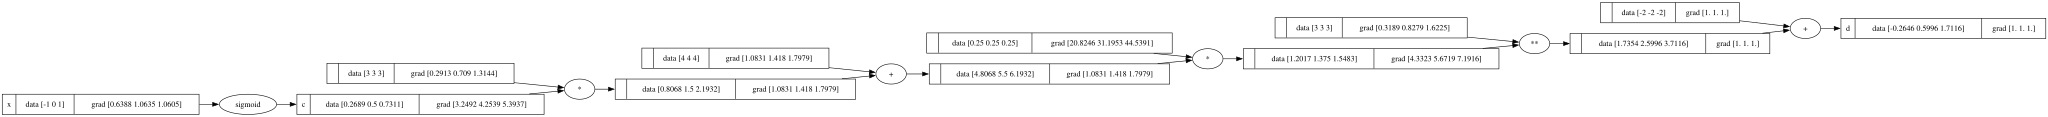

In [62]:
x = Tensor([-1, 0, 1], label="x")
print(Tensor.devices(), x.device)
a = x.tanh(); a.label="a"
b = x.relu(); b.label="b"
c = x.sigmoid(); c.label="c"
d = ((3*c + 4) / 4.0)**3 - 2; d.label="d"
d.backward()
draw_dot(d)

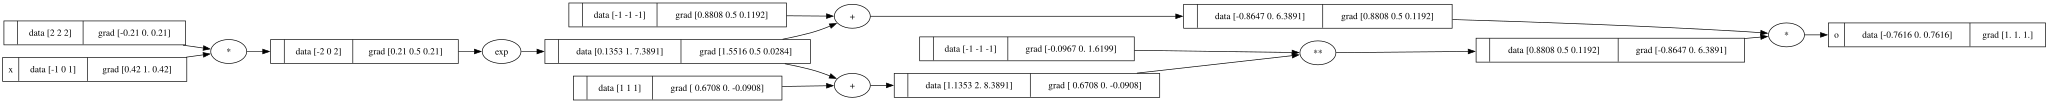

In [63]:
# EQUIVALENT but in longer form
x = Tensor([-1, 0, 1], label="x")
e = (2*x).exp()
o = (e - 1) / (e + 1); o.label="o"
o.backward()
draw_dot(o)

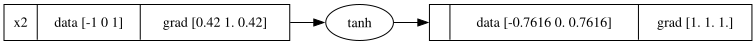

In [64]:
x2 = Tensor([-1, 0, 1], label="x2")
o2 = x2.tanh(); o2.backward()
draw_dot(o2)